# Step 3 — Taste communities

*Author: Cesi. Code: `src/taste.py` (functions), this notebook (runs them and explains the choices).*

**Question.** Do users who are friends on Yelp also share tastes? Step 2 built the **friend** partition of the 7,947 Philadelphia users. Here we build a **taste** partition of the *same* users, so step 5 can compare the two.

**Plan**
- **5.1** For each user, the set of things they like (two versions: restaurants and categories).
- **5.2** MinHash + LSH (from scratch) to find pairs of users with similar sets.
- **5.3** Taste-similarity graph → Louvain and Leiden communities.

## 0. Setup

All parameters are in this cell. Inputs are the files written by notebook 01 (`data/processed/philadelphia_pa_*.parquet`); nothing is recomputed from the raw Yelp JSON.

In [22]:
import sys
from pathlib import Path

import json, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# make src/ importable whether Jupyter was started from the repo root or from notebooks/
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT / "src"))

import importlib, taste, lsh, louvain
importlib.reload(taste); importlib.reload(lsh); importlib.reload(louvain)

# --- parameters -----------------------------------------------------------
SEED = 42
POSITIVE_COL = "is_positive"     # "liked" = stars >= 3.5, same definition as step 1
GENERIC_MAX_FRAC = 0.80          # drop categories liked by more than 80 % of the users (see the sweep)
GENERIC_SWEEP = (0.3, 0.5, 0.7, 0.8, 0.9)
MAX_CATS_PER_BUSINESS = 20       # only Reading Terminal Market (35 categories; next highest 17) is left out of the category version
MIN_BUSINESSES_PER_CATEGORY = 5  # categories present in fewer restaurants describe one place, not a kind of food

# 5.2 MinHash + LSH
N_HASHES = 240                   # signature length (b * r)
K_NEIGHBOURS = 10                # taste graph: each user is linked to its 10 most similar users
ROWS_RANGE = {"business": (2, 5), "category": (2, 6)}   # r values tried in the (b, r) sweep
MIN_RECALL = 0.90                # the chosen (b, r) must find >= 90 % of the true nearest neighbours
MAX_BUCKET = 1000                # skip LSH buckets with more users than this (reported)
FALLBACK_BRUTE_FORCE = True      # if no (b, r) reaches MIN_RECALL, use the exact neighbours (reported)

# 5.3 communities (same settings as Mattia's friend communities, notebook 02)
N_SEEDS = 20
RESOLUTION = 1.0

RESULTS = ROOT / "data" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
print("project root:", ROOT)

project root: c:\Users\cesia\OneDrive\Escriptori\C H E L S\DENMARK\DTU\computationa-tools-4DS\Computational-tools-4-datasciense


## 5.1 User sets

**What "liked" means.** A user likes a restaurant if `is_positive` is true (4 or 5 stars), the definition produced by step 1. We use the same definition as the rest of the project so that the friend partition, the taste partition and the association rules (step 4) talk about the same thing. The alternative, `stars_norm > 0` (above the user's own average), is kept as a possible robustness check.

**Two versions of each user's set**
1. **Restaurants**: the set of liked `business_id`s.
2. **Categories**: the set of categories of the liked restaurants.

Why two: friends may like the same restaurant simply because they went **together**, or because they were active in the **same years** (step 2 found that friend communities line up with the period of activity). Both inflate restaurant overlap between friends without meaning shared taste. Categories ("Thai", "Pizza") are much less affected.

We start from `categories_taste`, which step 1 already cleaned (it only removes `Restaurants`), and remove three kinds of categories that say nothing about taste:
- **Multi-purpose venues.** A few places (markets, food halls) are tagged with dozens of categories, many unrelated to food (*Sporting Goods, Department Stores, Dinner Theater…*). Liking one of them would add all those "tastes" at once; in a first run this created whole communities around a single venue. Restaurants with more than `MAX_CATS_PER_BUSINESS` = 20 categories are left out of the category version (they stay in the restaurant version). In practice this is only *Reading Terminal Market* (35 categories, twice the next one); a threshold of 10 would have removed 80 ordinary restaurants.
- **Rare categories**, present in fewer than `MIN_BUSINESSES_PER_CATEGORY` restaurants: they describe one place, not a kind of food.
- **Generic categories** that almost everybody likes (e.g. `Food`, `Nightlife`): they make every user look similar. We drop those liked by more than `GENERIC_MAX_FRAC` of the users.

In [23]:
reviews, businesses, users = taste.load_inputs(ROOT)
print(f"{len(reviews):,} reviews | {len(businesses):,} restaurants | {len(users):,} users")
print(f"share of reviews that are positive: {reviews[POSITIVE_COL].mean():.1%}")

251,375 reviews | 5,759 restaurants | 7,947 users
share of reviews that are positive: 69.5%


In [24]:
# categories per restaurant: most have a handful, a few venues have dozens
n_cats = businesses["categories_taste"].apply(len)
print("categories per restaurant, quantiles 50/90/99 %:", n_cats.quantile([.5, .9, .99]).tolist(), " max:", n_cats.max())
display(businesses.assign(n_categories=n_cats).nlargest(10, "n_categories")[["name", "n_categories"]])

_, CAT_INFO = taste.clean_business_categories(businesses, MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
print(f"venues left out of the category version (> {MAX_CATS_PER_BUSINESS} categories): {len(CAT_INFO['venues_dropped'])}")
print(f"rare categories dropped (< {MIN_BUSINESSES_PER_CATEGORY} restaurants): {CAT_INFO['rare_categories_dropped']}, e.g. {CAT_INFO['rare_categories_examples'][:12]}")

categories per restaurant, quantiles 50/90/99 %: [3.0, 7.0, 11.0]  max: 35


,name,n_categories
5458,Reading Terminal Market,35
3914,Avril 50,17
663,Hip Hemp Cafe,16
4340,Indian Kitchen Lovash,16
1426,Di Bruno Bros.,15
2426,Bistro Perrier,15
832,Johnny Brenda's,14
897,Milo - The Meeting House,14
2678,Garces Trading Company,14
4091,Philly Tacos,14


venues left out of the category version (> 20 categories): 1
rare categories dropped (< 5 restaurants): 170, e.g. ['Adult', 'Adult Education', 'Airport Lounges', 'Airport Shuttles', 'Apartments', 'Appliances', 'Arabic', 'Armenian', 'Art Classes', 'Art Museums', 'Australian', 'Austrian']


### Choosing the generic-category threshold

How many categories are dropped, and how many users end up with an empty set, for different thresholds.

A common choice would be ~30 %, but on Yelp it is far too aggressive: users like on average 22 restaurants, so they "like" most common categories. At 30 % we would drop 57 categories, including real cuisines such as *Italian, Chinese, Mexican, Thai, Japanese, Vegan*, which are exactly what describes a user's taste. We choose **80 %**: it removes only the 7 categories nearly everybody likes (from *Food*, 97 %, to *Sandwiches*, 83 %), and there is a natural gap before the next one (*Italian*, 74 %).

In [25]:
sweep = taste.generic_sweep(reviews, businesses, users, GENERIC_SWEEP, POSITIVE_COL,
                            MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
pd.set_option("display.max_colwidth", 120)
sweep

,max_frac,n_dropped,dropped,users_empty,set_size_mean
0,0.3,52,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian, Pizza, Coffe...",78,13.87
1,0.5,27,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian, Pizza, Coffe...",12,23.22
2,0.7,8,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian",6,34.16
3,0.8,7,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches",6,34.91
4,0.9,4,"Food, Nightlife, Bars, American (New)",6,37.45


In [26]:
sets_business = taste.build_user_sets(reviews, businesses, users, "business", POSITIVE_COL)
sets_category = taste.build_user_sets(reviews, businesses, users, "category", POSITIVE_COL, GENERIC_MAX_FRAC,
                                      MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)

summary_51 = pd.DataFrame([sets_business.summary(), sets_category.summary()]).set_index("version")
summary_51

,users_kept,users_empty,n_items,set_size_mean,set_size_median,set_size_min,set_size_max,generic_dropped
version,,,,,,,,
business,7941,6,5414,22.00,14.0,1,542,[]
category,7941,6,196,34.91,29.0,1,157,"[Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches]"


In [27]:
print("Generic categories dropped (share of users who like them):")
for c, f in sets_category.dropped_items.items():
    print(f"  {c:<25} {f:.1%}")

print("\nMost frequent categories kept:")
taste.item_popularity(sets_category, top=10)

Generic categories dropped (share of users who like them):
  Food                      96.6%
  Nightlife                 93.9%
  Bars                      93.3%
  American (New)            90.2%
  Breakfast & Brunch        88.0%
  American (Traditional)    83.2%
  Sandwiches                82.8%

Most frequent categories kept:


,item,n_users,share_users
0,Italian,5910,0.744239
1,Pizza,5512,0.694119
2,Coffee & Tea,5506,0.693364
3,Specialty Food,5046,0.635436
4,Mexican,4809,0.605591
5,Chinese,4792,0.603450
6,Cafes,4741,0.597028
7,Seafood,4665,0.587457
8,Cocktail Bars,4626,0.582546
9,Asian Fusion,4483,0.564538


### Period of activity (for step 5)

Median review year per user, with the same bins as notebook 02. Not used to build the taste communities; saved so that step 5 can control for it.

In [28]:
period = taste.user_activity_period(reviews)
period["period"].value_counts().sort_index()

period
<=2010     1060
2011-13    1841
2014-16    2329
>=2017     2717
Name: count, dtype: int64

### What we found (5.1)

- **7,941 of the 7,947 users** have a non-empty set in both versions. The 6 empty users have no 4–5-star review at all (not an effect of the filter); they are kept and flagged as isolated.
- **Restaurants:** 5,414 distinct restaurants; a user likes 22 on average (median 14, max 542).
- **Categories:** after leaving out Reading Terminal Market and 170 rare categories (present in < 5 restaurants), and dropping the 7 generic ones (*Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches*); see the summary table above for the final number of categories and set sizes.
- Category sets are **much denser** than restaurant sets, so Jaccard similarities are much higher in the category version (median of random pairs 0.19 vs 0.00).
- Limitation: the rare-category filter also removes a few genuine but very small cuisines (e.g. *Argentine, Armenian, Austrian*), which affects very few users.

## 5.2 MinHash + LSH: each user's most similar users

**Taste graph = k-nearest-neighbour graph.** Each user is linked to the `K_NEIGHBOURS` = 10 users whose sets are most similar (highest Jaccard), and the edge weight is that Jaccard.

*Why not a single similarity threshold?* We tried it first ("similar = more similar than 99.9 % of random pairs"): it left **85 % of the users isolated** in the category version and 20 % in the restaurant version. Jaccard depends strongly on set size, so users with few categories never reach a global threshold, and the communities would only describe the heaviest reviewers. With a kNN graph every user (with a non-empty set) has neighbours, whatever their absolute similarity.

**How LSH is used.** Finding each user's nearest neighbours exactly means comparing all 31.5 million pairs. LSH proposes **candidate pairs** instead:
1. **MinHash** turns each set into a signature of `N_HASHES` numbers; the share of equal positions in two signatures estimates their Jaccard.
2. **Banding** cuts the signature into `b` bands of `r` rows; two users are candidates if they are identical in at least one band. Probability $1-(1-s^r)^b$ (S-curve), threshold $t \approx (1/b)^{1/r}$.
3. For every candidate pair we compute the **exact** Jaccard and keep each user's top 10.

A pair is never a neighbour if its Jaccard is not above the **median Jaccard of random pairs** (`min_jaccard`): a "nearest neighbour" that is no more similar than a random user says nothing about taste.

Everything is implemented from scratch with NumPy in `src/lsh.py` ($h(x) = (a x + b) \bmod p$, $p = 2^{31}-1$). The exact kNN (**brute force** over all pairs) is the ground truth for recall and runtime.

In [29]:
SETS = {"business": sets_business, "category": sets_category}
X, SIG = {}, {}
for v, S in SETS.items():
    X[v] = lsh.sets_to_csr(S.sets, len(S.item_ids))
    t = time.perf_counter()
    SIG[v] = lsh.minhash_signatures(S.sets, N_HASHES, SEED, len(S.item_ids))
    print(f"{v:<9} signatures {SIG[v].shape}  in {time.perf_counter() - t:.2f} s")

# sanity check: MinHash estimate vs exact Jaccard on 2,000 random pairs
rng = np.random.default_rng(SEED)
for v, S in SETS.items():
    p = rng.integers(0, len(S.sets), (2000, 2)); p = p[p[:, 0] != p[:, 1]]
    est = np.array([lsh.minhash_estimate(SIG[v], a, b) for a, b in p])
    exact = lsh.pair_jaccard(X[v], p)
    print(f"{v:<9} mean |MinHash estimate - exact Jaccard| = {np.abs(est - exact).mean():.4f}")

business  signatures (7941, 240)  in 1.49 s
category  signatures (7941, 240)  in 2.72 s
business  mean |MinHash estimate - exact Jaccard| = 0.0023
category  mean |MinHash estimate - exact Jaccard| = 0.0218


### Similarity by chance and of the nearest neighbours

Jaccard of 200,000 random pairs (what "no particular similarity" looks like) versus the exact Jaccard of each user's 10th nearest neighbour (the similarity LSH has to detect).

In [30]:
rand_j = {v: lsh.random_pair_jaccard(X[v], 200_000, SEED) for v in SETS}
MIN_J = {v: float(np.median(rand_j[v])) for v in SETS}

TRUTH, T_BRUTE = {}, {}
for v in SETS:
    t = time.perf_counter()
    TRUTH[v] = lsh.brute_force_knn(X[v], K_NEIGHBOURS, MIN_J[v])
    T_BRUTE[v] = time.perf_counter() - t
KTH = {v: TRUTH[v].groupby("user")["jaccard"].min() for v in SETS}     # J of each user's k-th neighbour

pd.DataFrame({v: {"random pairs: median J (= min_jaccard)": MIN_J[v],
                  "random pairs: 99th pct": np.quantile(rand_j[v], .99),
                  "random pairs: share with J = 0": np.mean(rand_j[v] == 0),
                  f"{K_NEIGHBOURS}th neighbour: median J": KTH[v].median(),
                  f"{K_NEIGHBOURS}th neighbour: 10th pct J": KTH[v].quantile(.1),
                  "users with < k neighbours above min_jaccard": int((TRUTH[v].groupby('user').size() < K_NEIGHBOURS).sum()
                                                                    + len(SETS[v].sets) - TRUTH[v]['user'].nunique()),
                  "brute force kNN time (s)": T_BRUTE[v]} for v in SETS}).round(3)

,business,category
random pairs: median J (= min_jaccard),0.000,0.200
random pairs: 99th pct,0.071,0.476
random pairs: share with J = 0,0.737,0.007
10th neighbour: median J,0.100,0.435
10th neighbour: 10th pct J,0.075,0.350
users with < k neighbours above min_jaccard,2.000,11.000
brute force kNN time (s),8.104,13.325


### Choosing (b, r)

For each version we try several splits of the `N_HASHES` hash functions into `b` bands × `r` rows and record the number of candidates, the **recall** (share of the exact 10 nearest neighbours that LSH also finds) and the runtime. We keep the **cheapest configuration (fewest candidates) with recall ≥ 90 %**. If none reaches it, we use the exact neighbours from the brute force and say so.

In [31]:
SWEEP, FOUND, CHOSEN = {}, {}, {}
for v, S in SETS.items():
    configs = lsh.band_configs(N_HASHES, ROWS_RANGE[v][1], ROWS_RANGE[v][0])
    SWEEP[v], FOUND[v] = lsh.knn_sweep(S.sets, len(S.item_ids), configs, K_NEIGHBOURS, TRUTH[v],
                                       MIN_J[v], SEED, MAX_BUCKET)
    best = lsh.choose_config(SWEEP[v], MIN_RECALL)
    reached = SWEEP[v].set_index(["bands", "rows"]).loc[best, "recall"] >= MIN_RECALL
    CHOSEN[v] = best if (reached or not FALLBACK_BRUTE_FORCE) else "brute force"

cols = ["bands", "rows", "t_approx", "n_candidates", "recall", "users_without_neighbour",
        "n_buckets_skipped", "max_bucket_seen", "time_total_s"]
for v in SETS:
    print(f"\n{v}: exact kNN (brute force) {T_BRUTE[v]:.1f} s -> chosen: {CHOSEN[v]}")
    display(SWEEP[v][cols])


business: exact kNN (brute force) 8.1 s -> chosen: brute force


,bands,rows,t_approx,n_candidates,recall,users_without_neighbour,n_buckets_skipped,max_bucket_seen,time_total_s
0,120,2,0.091,1146370,0.8209,2,0,369,46.54
1,80,3,0.232,53512,0.1594,811,0,102,9.00
2,60,4,0.359,2827,0.0209,5722,0,21,4.40
3,48,5,0.461,239,0.0036,7559,0,5,3.60



category: exact kNN (brute force) 13.3 s -> chosen: (80, 3)


,bands,rows,t_approx,n_candidates,recall,users_without_neighbour,n_buckets_skipped,max_bucket_seen,time_total_s
0,120,2,0.091,24155652,1.0000,1,76,3499,177.17
1,80,3,0.232,13297572,0.9936,2,2,1396,69.67
2,60,4,0.359,5187350,0.8872,5,0,872,35.98
3,48,5,0.461,1666893,0.6157,43,0,385,18.36
4,40,6,0.541,592754,0.3609,176,0,324,8.11


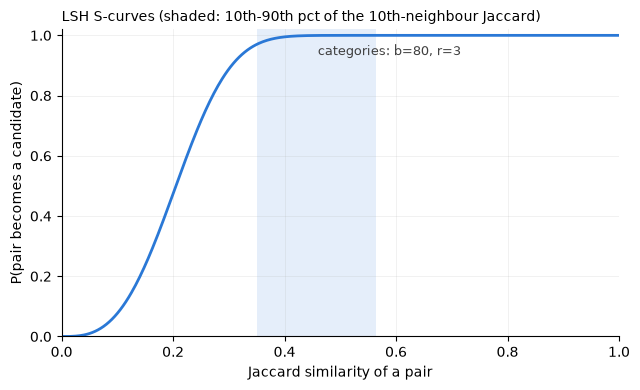

In [32]:
# S-curves of the chosen configurations, with the distribution of the 10th-neighbour Jaccard (figure for the report)
s = np.linspace(0, 1, 400)
colors = {"category": "#2a78d6", "business": "#eb6834"}
names = {"category": "categories", "business": "restaurants"}
fig, ax = plt.subplots(figsize=(6.5, 4))
for v in SETS:
    if CHOSEN[v] == "brute force":
        continue
    b, r = CHOSEN[v]
    ax.plot(s, lsh.s_curve(s, b, r), color=colors[v], lw=2)
    lo, med = KTH[v].quantile(.1), KTH[v].median()
    ax.axvspan(lo, KTH[v].quantile(.9), color=colors[v], alpha=0.12, lw=0)
    ax.annotate(f"{names[v]}: b={b}, r={r}", (med, lsh.s_curve(med, b, r)),
                xytext=(10, -14), textcoords="offset points", fontsize=9, color="0.25")
ax.set_xlabel("Jaccard similarity of a pair")
ax.set_ylabel("P(pair becomes a candidate)")
ax.set_title("LSH S-curves (shaded: 10th-90th pct of the 10th-neighbour Jaccard)", loc="left", fontsize=10)
ax.grid(alpha=0.25, lw=0.5); ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
fig.tight_layout(); fig.savefig(FIGURES / "03_lsh_s_curves.png", dpi=150)
plt.show()

### Save the taste-graph edges

Undirected kNN graph: edge u–v if v is among u's 10 nearest neighbours **or** u among v's. One file per version with the original Yelp ids, plus a JSON with the numbers of 5.1 and 5.2.

In [33]:
EDGES = {}
for v, S in SETS.items():
    d = TRUTH[v] if CHOSEN[v] == "brute force" else FOUND[v][CHOSEN[v]]
    e = lsh.knn_edges(d)
    EDGES[v] = pd.DataFrame({"u": S.user_ids[e["u"].to_numpy()], "v": S.user_ids[e["v"].to_numpy()],
                             "jaccard": e["jaccard"].to_numpy()})
    EDGES[v].to_parquet(RESULTS / f"taste_edges_{v}.parquet", index=False)
    print(f"{v:<9} {len(EDGES[v]):,} edges saved")

def row(v):
    base = {"min_jaccard": round(MIN_J[v], 4), "kth_neighbour_median_j": round(float(KTH[v].median()), 4),
            "n_edges": len(EDGES[v]), "time_brute_force_s": round(T_BRUTE[v], 2)}
    if CHOSEN[v] == "brute force":
        best = SWEEP[v].loc[SWEEP[v]["recall"].idxmax()]
        return {**base, "method": "brute force (LSH recall too low)",
                "best_lsh": f"b={int(best['bands'])}, r={int(best['rows'])}: recall {best['recall']:.2f}"}
    r = SWEEP[v].set_index(["bands", "rows"]).loc[CHOSEN[v]]
    return {**base, "method": "LSH", "bands": CHOSEN[v][0], "rows": CHOSEN[v][1],
            "t_approx": float(r["t_approx"]), "n_candidates": int(r["n_candidates"]),
            "recall": float(r["recall"]), "time_lsh_s": float(r["time_total_s"]),
            "buckets_skipped": int(r["n_buckets_skipped"])}

summary = {"params": {"seed": SEED, "positive": POSITIVE_COL, "generic_max_frac": GENERIC_MAX_FRAC,
                      "max_cats_per_business": MAX_CATS_PER_BUSINESS,
                      "min_businesses_per_category": MIN_BUSINESSES_PER_CATEGORY,
                      "venues_dropped": CAT_INFO["venues_dropped"],
                      "rare_categories_dropped": CAT_INFO["rare_categories_dropped"],
                      "n_hashes": N_HASHES, "k_neighbours": K_NEIGHBOURS,
                      "min_recall": MIN_RECALL, "max_bucket": MAX_BUCKET},
           "user_sets": {v: S.summary() for v, S in SETS.items()},
           "lsh": {v: row(v) for v in SETS}}
(RESULTS / "taste_summary.json").write_text(json.dumps(summary, indent=2, default=str))
pd.DataFrame(summary["lsh"])

business  61,360 edges saved
category  65,063 edges saved


,business,category
min_jaccard,0.0,0.2
kth_neighbour_median_j,0.1,0.4348
n_edges,61360,65063
time_brute_force_s,8.1,13.32
method,brute force (LSH recall too low),LSH
best_lsh,"b=120, r=2: recall 0.82",NaN
bands,NaN,80
rows,NaN,3
t_approx,NaN,0.232
n_candidates,NaN,13297572


### What we found (5.2)

- **The nearest neighbours are meaningful.** A user's 10th most similar user has a median Jaccard of **0.43** (categories) and **0.10** (restaurants), against 0.19 and 0.00 for random pairs (74 % of random pairs share no liked restaurant).
- **A kNN graph instead of a global threshold.** A global threshold (top 0.1 % of random pairs) left 85 % of the users isolated in the category version, because Jaccard depends on set size. With 10 neighbours per user only the 6–7 users without a set are isolated and the graph is connected.
- **Categories: LSH works.** b = 80, r = 3 finds **99.5 %** of the exact neighbours. The sweep shows the trade-off: r = 2 → 23.9 M candidates (recall 1.00); r = 4 → 5.0 M (0.88); r = 6 → 0.7 M (0.38).
- **Restaurants: LSH is not enough.** The best configuration (b = 120, r = 2) only reaches recall **0.82**: the similarities we look for are low (J ≈ 0.10), and LSH is efficient only for high similarities. We use the exact neighbours from the brute force.
- **At this size brute force is faster** (2–4 s vs 74 s for LSH in the category version). Exact all-pairs comparison grows with n² (31.5 M pairs here) but still fits in a sparse matrix product; LSH grows roughly linearly and would pay off for the whole Yelp data (~2 M users), not for one city.

## 5.3 Taste-similarity graph and communities

**Graph.** One node per user (all 7,947, as in the friend graph), one edge per kNN pair from 5.2, **weight = Jaccard**: more similar pairs pull harder towards the same community. The few users without neighbours (empty set) stay as isolated nodes; each becomes its own community and is flagged (`isolated_*`), so step 5 can include or exclude them consistently.

**Algorithm.** We reuse **Mattia's Louvain written from scratch** (notebook 02, now in `src/louvain.py`), so both partitions are found with exactly the same method. The only change is that it can read edge weights (with `weight=None` it gives the same results as before). As in step 2 we run **20 seeds**, keep the run with the highest modularity, fix the communities that Louvain leaves internally disconnected (`split_disconnected`), and report stability between seeds.

In [34]:
# check of the weighted extension: our modularity equals networkx's on a weighted graph
import networkx as nx
K = nx.karate_club_graph()                      # has edge weights
p, _ = louvain.louvain(K, seed=0, weight="weight")
groups = [{u for u in p if p[u] == c} for c in set(p.values())]
print("weighted modularity, ours:", round(louvain.modularity(K, p, weight="weight"), 4),
      " networkx:", round(nx.community.modularity(K, groups, weight="weight"), 4))

weighted modularity, ours: 0.4439  networkx: 0.4439


In [35]:
ALL_USERS = users["user_id"].to_numpy()
G_TASTE, RUNS, PARTS, BEST = {}, {}, {}, {}
for v in SETS:
    G = taste.build_taste_graph(ALL_USERS, EDGES[v])
    G_TASTE[v] = G
    t = time.perf_counter()
    RUNS[v], PARTS[v] = taste.louvain_seeds(G, N_SEEDS, RESOLUTION, weight="weight")
    BEST[v] = int(RUNS[v].loc[RUNS[v]["modularity"].idxmax(), "seed"])
    n_iso = sum(1 for _, d in G.degree() if d == 0)
    n_comp = nx.number_connected_components(G.subgraph([u for u, d in G.degree() if d > 0]))
    print(f"{v:<9} {G.number_of_nodes():,} users, {G.number_of_edges():,} edges, {n_iso} isolated, "
          f"{n_comp} connected components (without isolated) | {N_SEEDS} Louvain runs in {time.perf_counter() - t:.0f} s")

business  7,947 users, 61,360 edges, 6 isolated, 1 connected components (without isolated) | 20 Louvain runs in 88 s
category  7,947 users, 65,063 edges, 8 isolated, 1 connected components (without isolated) | 20 Louvain runs in 92 s


In [36]:
# diagnostic: are the isolated users the ones with small sets? (degree vs set size)
rows = []
for v, S in SETS.items():
    deg = dict(G_TASTE[v].degree())
    d = pd.DataFrame({"size": S.sizes, "degree": [deg[u] for u in S.user_ids]})
    d["size group"] = pd.qcut(d["size"], 4, labels=["Q1 (smallest sets)", "Q2", "Q3", "Q4 (largest sets)"])
    g = d.groupby("size group", observed=True).agg(set_size=("size", "median"), mean_degree=("degree", "mean"),
                                                   isolated=("degree", lambda x: (x == 0).mean()))
    g["version"] = v
    rows.append(g.reset_index())
pd.concat(rows).set_index(["version", "size group"]).round(2)

set_size  mean_degree  isolated
version  size group                                         
business Q1 (smallest sets)       8.0        17.65       0.0
         Q2                      12.0        15.08       0.0
         Q3                      18.0        14.52       0.0
         Q4 (largest sets)       40.0        14.23       0.0
category Q1 (smallest sets)      16.0        13.30       0.0
         Q2                      25.0        14.67       0.0
         Q3                      35.0        16.79       0.0
         Q4 (largest sets)       59.0        21.03       0.0

In [37]:
def describe_runs(v):
    r, best = RUNS[v], RUNS[v].set_index("seed").loc[BEST[v]]
    sizes = pd.Series(PARTS[v][BEST[v]]).value_counts()
    non_iso = [u for u, d in G_TASTE[v].degree() if d > 0]
    stab = taste.pairwise_stability(PARTS[v], non_iso)
    return {"modularity (best run)": round(best["modularity"], 4),
            "modularity (mean ± sd, 20 seeds)": f"{r['modularity'].mean():.3f} ± {r['modularity'].std():.3f}",
            "best seed": BEST[v],
            "communities (best run)": int(best["n_communities"]),
            "communities with >= 50 users": int(best["n_communities_ge_50"]),
            "share of users in 5 largest": f"{best['share_users_in_5_largest']:.0%}",
            "5 largest sizes": " / ".join(str(x) for x in sizes.iloc[:5]),
            "disconnected communities fixed (all runs)": int(r["n_disconnected_fixed"].sum()),
            "runs with a disconnected community": int((r["n_disconnected_fixed"] > 0).sum()),
            "stability ARI mean (min)": f"{stab['ARI_mean']:.2f} ({stab['ARI_min']:.2f})",
            "stability NMI mean (min)": f"{stab['NMI_mean']:.2f} ({stab['NMI_min']:.2f})"}

COMM_SUMMARY = pd.DataFrame({v: describe_runs(v) for v in SETS})
COMM_SUMMARY

,business,category
modularity (best run),0.4475,0.4886
"modularity (mean ± sd, 20 seeds)",0.442 ± 0.003,0.478 ± 0.006
best seed,3,18
communities (best run),18,17
communities with >= 50 users,12,9
share of users in 5 largest,69%,80%
5 largest sizes,1450 / 1353 / 964 / 899 / 805,1539 / 1303 / 1248 / 1163 / 1087
disconnected communities fixed (all runs),1,0
runs with a disconnected community,1,0
stability ARI mean (min),0.39 (0.29),0.32 (0.19)


### Null model: are these communities real?

Same check as in step 2: modularity of Louvain on random graphs with the **same degrees** (and the same edge weights, shuffled). If the real modularity is much higher, the communities are not an artefact of the degree distribution.

In [38]:
null_q = {}
for v in SETS:
    G = G_TASTE[v]
    qs = []
    for s in range(3):
        R = nx.Graph(nx.configuration_model([d for _, d in G.degree()], seed=s))
        R.remove_edges_from(nx.selfloop_edges(R))
        R = nx.relabel_nodes(R, dict(enumerate(G.nodes())))
        w = np.random.default_rng(s).permutation(EDGES[v]["jaccard"].to_numpy())
        for (a, b), x in zip(R.edges(), w):
            R[a][b]["weight"] = x
        p, _ = louvain.louvain(R, RESOLUTION, seed=s, weight="weight")
        qs.append(louvain.modularity(R, p, RESOLUTION, "weight"))
    null_q[v] = np.mean(qs)
    print(f"{v:<9} modularity: real {RUNS[v]['modularity'].max():.3f}   random graphs with same degrees {null_q[v]:.3f}")

business  modularity: real 0.447   random graphs with same degrees 0.229
category  modularity: real 0.489   random graphs with same degrees 0.201


### What characterises each taste community?

For the category version, the categories that are most **over-represented** in each large community (liked by ≥ 25 % of its members, ranked by lift = share in the community / share among all users). This is a sanity check that the communities mean something, and gives names for the report.

In [39]:
pd.set_option("display.max_colwidth", 200)
taste.community_profile(sets_category, PARTS["category"][BEST["category"]], min_size=50)

,community,size,"top categories (share in community, lift)"
0,0,1539,"Japanese (66%, ×1.3); Sushi Bars (58%, ×1.2); Asian Fusion (63%, ×1.1); Chinese (64%, ×1.1); Thai (37%, ×1.0)"
1,1,1303,"Cheesesteaks (37%, ×1.0); Pizza (66%, ×1.0); Delis (34%, ×0.9); Italian (68%, ×0.9); Burgers (43%, ×0.8)"
2,2,1248,"Music Venues (41%, ×2.4); Irish (28%, ×2.3); Arts & Entertainment (57%, ×1.9); Sports Bars (54%, ×1.8); Dive Bars (26%, ×1.8)"
3,3,1163,"Bubble Tea (37%, ×2.9); Taiwanese (28%, ×2.9); Ramen (46%, ×2.6); Cantonese (27%, ×2.6); Shanghainese (28%, ×2.5)"
4,4,1087,"Arts & Crafts (25%, ×3.4); German (33%, ×3.2); Street Vendors (30%, ×3.2); Butcher (25%, ×3.1); Malaysian (25%, ×3.1)"
5,5,855,"Iberian (39%, ×3.1); Tapas Bars (69%, ×3.0); Spanish (64%, ×2.9); Modern European (43%, ×2.3); Cuban (30%, ×1.9)"
6,6,366,"Art Galleries (36%, ×8.6); Seafood Markets (46%, ×7.8); Meat Shops (52%, ×7.1); Museums (36%, ×6.5); Fruits & Veggies (57%, ×6.5)"
7,7,324,"Beer Gardens (58%, ×3.3); Active Life (56%, ×3.0); Grocery (57%, ×2.5); Middle Eastern (69%, ×1.8); Cafes (85%, ×1.4)"
8,8,54,"Kebab (81%, ×27.7); Filipino (80%, ×25.3); Falafel (89%, ×9.1); Tacos (87%, ×5.3); Beer Bar (89%, ×2.8)"


In [40]:
# same description for the restaurant-based communities (described with their members' categories)
taste.community_profile(sets_category, PARTS["business"][BEST["business"]], min_size=50)

,community,size,"top categories (share in community, lift)"
0,0,1450,"Whiskey Bars (33%, ×2.7); German (27%, ×2.7); Cheese Shops (37%, ×2.6); Iberian (33%, ×2.6); Falafel (25%, ×2.6)"
1,1,1353,"Middle Eastern (52%, ×1.4); Active Life (25%, ×1.3); Tapas/Small Plates (46%, ×1.3); Wine Bars (55%, ×1.2); Mediterranean (60%, ×1.2)"
2,2,964,"Cheesesteaks (59%, ×1.5); Shopping (29%, ×1.4); Delis (44%, ×1.2); Local Flavor (36%, ×1.1); Bakeries (49%, ×1.0)"
3,3,899,"Tapas Bars (26%, ×1.1); Lounges (48%, ×1.1); Latin American (32%, ×1.1); Pubs (52%, ×1.0); Italian (72%, ×1.0)"
4,4,805,"Dive Bars (25%, ×1.7); Music Venues (26%, ×1.5); Arts & Entertainment (42%, ×1.4); Southern (30%, ×1.3); Beer Bar (40%, ×1.3)"
5,5,772,"Bubble Tea (28%, ×2.2); Ramen (35%, ×2.0); Korean (52%, ×1.8); Dim Sum (43%, ×1.7); Noodles (50%, ×1.6)"
6,6,447,"Breweries (32%, ×1.8); Delis (55%, ×1.5); Cheesesteaks (50%, ×1.3); Beer Bar (38%, ×1.2); Pizza (81%, ×1.2)"
7,7,345,"Halal (34%, ×2.0); Indian (44%, ×1.6); Food Delivery Services (30%, ×1.3); Vegetarian (68%, ×1.2); Middle Eastern (44%, ×1.2)"
8,8,267,"Buffets (31%, ×2.9); Steakhouses (58%, ×1.7); Chicken Wings (45%, ×1.6); Barbeque (53%, ×1.5); Delis (49%, ×1.4)"
9,9,234,"Vegetarian (56%, ×1.0); Mexican (58%, ×1.0); Italian (71%, ×1.0); Pizza (66%, ×0.9); Coffee & Tea (65%, ×0.9)"


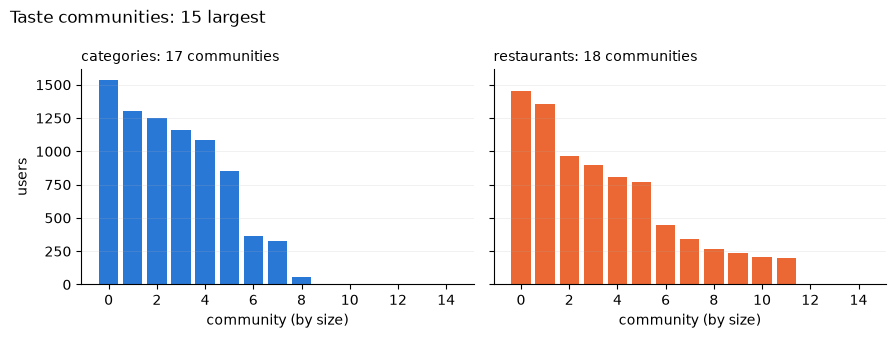

In [41]:
# figure: community sizes of the chosen partitions
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, v in zip(axes, ["category", "business"]):
    sizes = pd.Series(PARTS[v][BEST[v]]).value_counts().to_numpy()
    top = sizes[:15]
    ax.bar(range(len(top)), top, color=colors[v], width=0.8)
    ax.set_title(f"{names[v]}: {len(sizes)} communities", loc="left", fontsize=10)
    ax.set_xlabel("community (by size)")
    ax.set_xticks(range(0, len(top), 2))
    ax.grid(axis="y", alpha=0.25, lw=0.5); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("users")
fig.suptitle("Taste communities: 15 largest", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURES / "03_taste_community_sizes.png", dpi=150)
plt.show()

### Save the taste communities (contract with step 5)

`data/results/taste_communities.parquet`, one row per user of `philadelphia_pa_users.parquet` (7,947):

| column | meaning |
|---|---|
| `user_id` | original Yelp id |
| `louvain_business`, `louvain_category` | community of the chosen run (0 = largest; labels are arbitrary, compare groupings only) |
| `isolated_business`, `isolated_category` | True if the user has no similar pair (singleton community) |
| `median_year`, `period` | user's median review year and period bin (same bins as notebook 02), to control for the period-of-activity confounder |

Plus `taste_communities_all_seeds_{business,category}.parquet` (columns `seed_0` … `seed_19`) for the robustness check over the 20 runs, like step 2.

In [42]:
out = pd.DataFrame({"user_id": ALL_USERS})
for v in SETS:
    out[f"louvain_{v}"] = out["user_id"].map(PARTS[v][BEST[v]]).astype("int64")
    deg = dict(G_TASTE[v].degree())
    out[f"isolated_{v}"] = out["user_id"].map(lambda u: deg[u] == 0)
    seeds = pd.DataFrame({"user_id": ALL_USERS})
    for s, p in PARTS[v].items():
        seeds[f"seed_{s}"] = seeds["user_id"].map(p).astype("int64")
    seeds.to_parquet(RESULTS / f"taste_communities_all_seeds_{v}.parquet", index=False)
out = out.merge(period.reset_index(), on="user_id", how="left")
out["period"] = out["period"].astype(str)
out.to_parquet(RESULTS / "taste_communities.parquet", index=False)

summary["communities"] = {v: {**COMM_SUMMARY[v].to_dict(), "modularity_null": round(null_q[v], 4)} for v in SETS}
summary["params"].update({"n_seeds": N_SEEDS, "resolution": RESOLUTION})
(RESULTS / "taste_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(out.shape); out.head()

(7947, 7)


,user_id,louvain_business,isolated_business,louvain_category,isolated_category,median_year,period
0,--pMssoWlOqX0pLiPMiZZw,6,False,0,False,2012.0,2011-13
1,-0vutwuE36iYMqM2wHaStQ,5,False,0,False,2009.0,<=2010
2,-1MF2tosrw2WcCxeVNk81Q,5,False,7,False,2017.0,>=2017
3,-2cKJFFNJ9XVyWBt62mWvA,0,False,6,False,2019.0,>=2017
4,-33OBttPeyt_pUozPxkFEg,10,False,3,False,2019.0,>=2017


### What we found (5.3)

- **Real communities.** Modularity **0.489** (categories) and **0.447** (restaurants), against **0.201** and **0.229** for random graphs with the same degrees.
- **Size.** 17 communities (categories; 9 with ≥ 50 users, 5 largest = 80 % of users) and 18 (restaurants; 12 with ≥ 50 users, 69 %).
- **Interpretable.** Most category communities have a clear profile: Japanese & sushi; pizza, cheesesteaks & Italian; pubs, sports bars & live music; bubble tea, ramen & Taiwanese/Cantonese; tapas & Spanish. The restaurant-based communities are similar (e.g. Korean & dim sum, Indian & halal, vegan & kosher).
- **Moderate stability.** ARI between seeds 0.32 (categories) and 0.39 (restaurants), lower than for the friend communities (0.54). The 20 runs are saved so that step 5 can report the spread, not only the chosen run.
- **Louvain defect.** Internally disconnected communities appeared in only 1 of 40 runs (fixed afterwards).
- **Limitation.** Two category communities (366 and 54 users) are still largely built around a single multi-category venue (market / food hall); together ~5 % of the users.